# 03 - Exploratory Data Analysis (EDA)

This notebook explores the cleaned dataset with charts and simple summaries.
The goal is to **look for patterns** between each factor and the final grade (`G3`) before any formal statistical testing.

Each section answers one of the five research questions from the README.

> Note: EDA can only *suggest* relationships. Whether a pattern is real (and not due to chance) is tested in Stage 4.

## Setup

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

One shared chart style for the whole notebook, so every figure looks consistent.
A single blue is used for all charts because each chart shows only one thing (`G3`), so no legend is needed.

In [2]:
BLUE = '#2a78d6'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['grid.color'] = '#e6e6e3'
plt.rcParams['axes.titleweight'] = 'bold'

FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

The cleaned file was saved with commas, so `sep=';'` is not needed here.

In [3]:
df = pd.read_csv('../data/processed/student-por-clean.csv')
df.shape

(634, 33)

## The Outcome: Final Grade (G3)

In [4]:
df['G3'].describe()

count    634.000000
mean      12.187697
std        2.691824
min        1.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

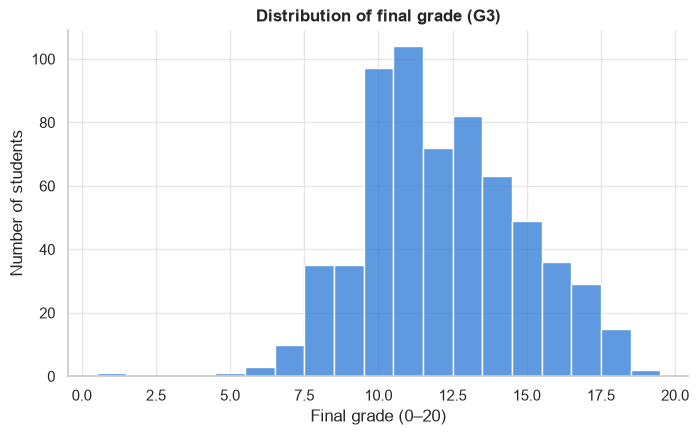

In [5]:
ax = sns.histplot(data=df, x='G3', discrete=True, color=BLUE)
ax.set_title('Distribution of final grade (G3)')
ax.set_xlabel('Final grade (0–20)')
ax.set_ylabel('Number of students')
plt.savefig(f'{FIG_DIR}/g3_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Final grades cluster in the middle of the scale. The average is about 12.2 and half of all students score between 10 and 14. Very low and very high grades are rare.

## Q1. Is study time associated with final grade?

`studytime` is a code, not hours: 1 = <2h, 2 = 2–5h, 3 = 5–10h, 4 = >10h per week.
Because it is a small set of groups, a **box plot** per group is a good fit.

How to read a box plot: the line in the middle is the median, the box holds the middle 50% of students, and dots are unusual values (outliers).

In [6]:
df.groupby('studytime')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
studytime,,,
1,204,11.27,11.0
2,298,12.38,12.0
3,97,13.23,13.0
4,35,13.06,13.0


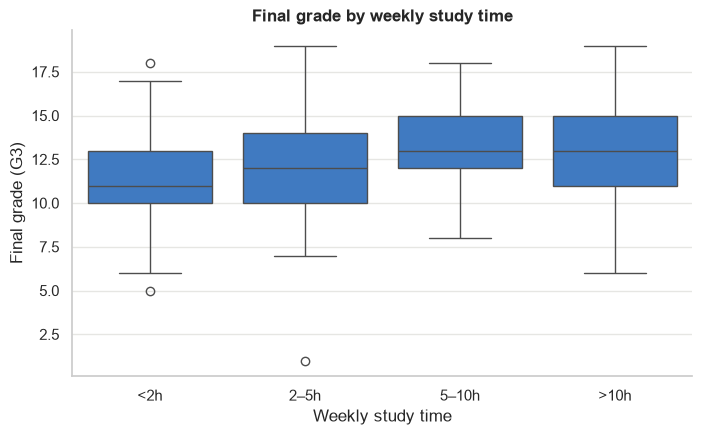

In [7]:
ax = sns.boxplot(data=df, x='studytime', y='G3', color=BLUE)
ax.set_title('Final grade by weekly study time')
ax.set_xticks(range(4))
ax.set_xticklabels(['<2h', '2–5h', '5–10h', '>10h'])
ax.set_xlabel('Weekly study time')
ax.set_ylabel('Final grade (G3)')
plt.savefig(f'{FIG_DIR}/g3_by_studytime.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Grades appear to rise with study time, from an average of about 11.3 (<2h) to about 13.2 (5–10h). The >10h group does not continue the rise, but it only has 35 students, so its average is less reliable.

## Q2. Are absences associated with final grade?

`absences` is a real count (number of school days missed), so a **scatter plot** is used.

In [8]:
df['absences'].describe()

count    634.000000
mean       3.746057
std        4.660702
min        0.000000
25%        0.000000
50%        2.000000
75%        6.000000
max       32.000000
Name: absences, dtype: float64

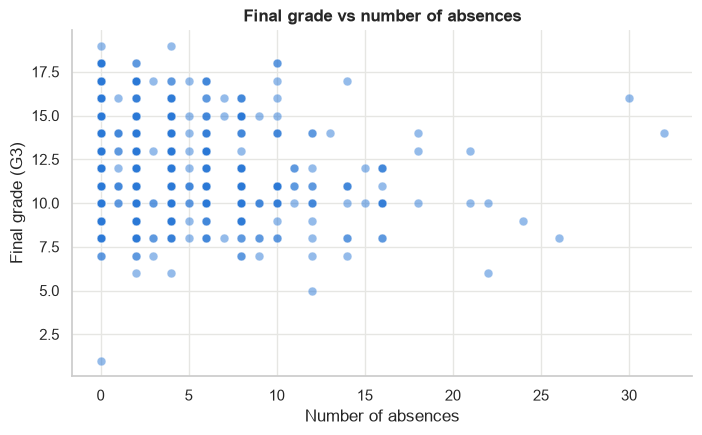

In [9]:
ax = sns.scatterplot(data=df, x='absences', y='G3', color=BLUE, alpha=0.5, s=40)
ax.set_title('Final grade vs number of absences')
ax.set_xlabel('Number of absences')
ax.set_ylabel('Final grade (G3)')
plt.savefig(f'{FIG_DIR}/g3_vs_absences.png', dpi=150, bbox_inches='tight')
plt.show()

A **correlation** is a single number from -1 to 1 that measures how two numeric columns move together. Near 0 means no straight-line relationship; negative means one goes up as the other goes down.

In [10]:
df['absences'].corr(df['G3']).round(3)

np.float64(-0.196)

In [11]:
(df['absences'] > 15).sum()

np.int64(21)

**Observation:** Most students have few absences (median = 2), but a small number have a lot (max = 32; 21 students have more than 15). There appears to be a weak negative relationship (correlation ≈ -0.20): students with more absences tend to score slightly lower, but the points are widely scattered.

## Q3. Are previous failures associated with final grade?

`failures` codes: 0 = never failed, 1 = once, 2 = twice, 3 = three or more times.

In [12]:
df['failures'].value_counts().sort_index()

failures
0    543
1     63
2     15
3     13
Name: count, dtype: int64

In [13]:
df.groupby('failures')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
failures,,,
0,543,12.65,12.0
1,63,9.60,10.0
2,15,9.40,10.0
3,13,8.69,9.0


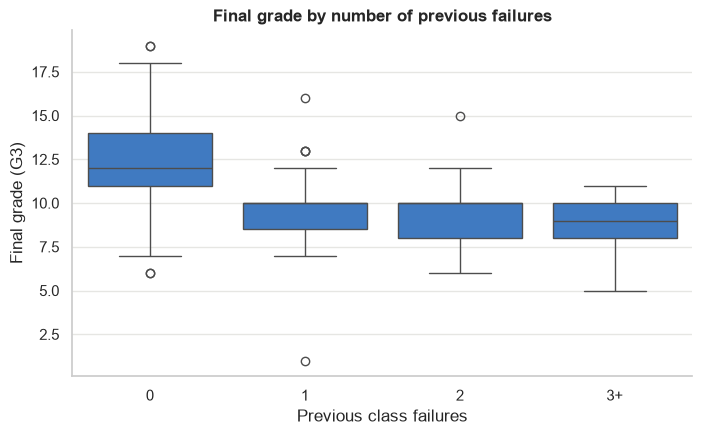

In [14]:
ax = sns.boxplot(data=df, x='failures', y='G3', color=BLUE)
ax.set_title('Final grade by number of previous failures')
ax.set_xticks(range(4))
ax.set_xticklabels(['0', '1', '2', '3+'])
ax.set_xlabel('Previous class failures')
ax.set_ylabel('Final grade (G3)')
plt.savefig(f'{FIG_DIR}/g3_by_failures.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** This is the clearest pattern so far. Students who never failed average about 12.7, while students with any failure average below 10. However, most students (543 of 634) have 0 failures, and the 2 and 3+ groups are very small (15 and 13 students).

## Q4. Is parental education associated with final grade?

`Medu` (mother) and `Fedu` (father) codes: 0 = none, 1 = primary, 2 = 5th–9th grade, 3 = secondary, 4 = higher education.
The two charts are placed side by side with the same y-axis so they are easy to compare.

In [15]:
df.groupby('Medu')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
Medu,,,
0,6,11.67,11.0
1,138,11.19,11.0
2,181,11.98,12.0
3,138,12.01,12.0
4,171,13.37,13.0


In [16]:
df.groupby('Fedu')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
Fedu,,,
0,7,12.14,11.0
1,167,11.40,11.0
2,202,12.19,12.0
3,131,12.38,12.0
4,127,13.02,13.0


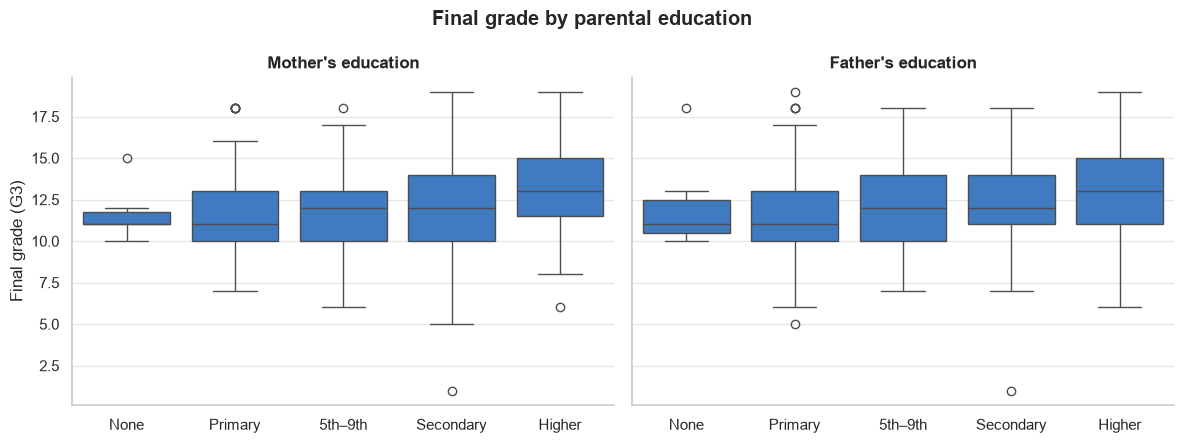

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
edu_labels = ['None', 'Primary', '5th–9th', 'Secondary', 'Higher']

sns.boxplot(data=df, x='Medu', y='G3', color=BLUE, ax=axes[0])
axes[0].set_title("Mother's education")
axes[0].set_xlabel('')
axes[0].set_ylabel('Final grade (G3)')

sns.boxplot(data=df, x='Fedu', y='G3', color=BLUE, ax=axes[1])
axes[1].set_title("Father's education")
axes[1].set_xlabel('')

for ax in axes:
    ax.set_xticks(range(5))
    ax.set_xticklabels(edu_labels)

fig.suptitle('Final grade by parental education', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/g3_by_parent_education.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Students whose parents have higher education tend to score higher. The difference is clearest for mothers (about 11.2 for primary vs 13.4 for higher education). The "None" groups are tiny (6 and 7 students), so their results should not be trusted on their own.

## Q5. Does final grade differ between the two schools?

GP = Gabriel Pereira, MS = Mousinho da Silveira.

In [18]:
df.groupby('school')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
school,,,
GP,422,12.61,13.0
MS,212,11.35,11.0


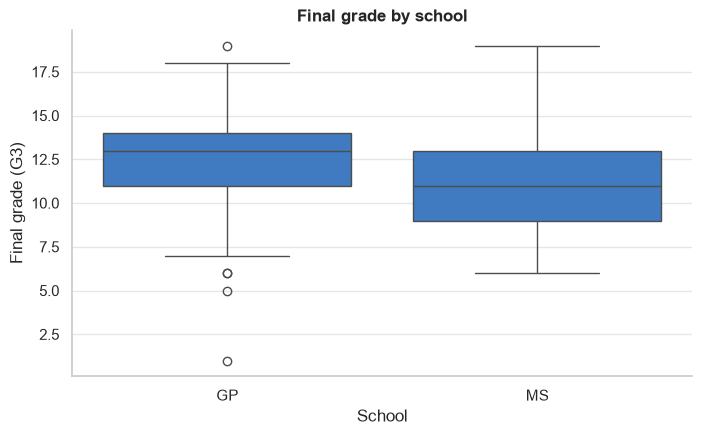

In [19]:
ax = sns.boxplot(data=df, x='school', y='G3', color=BLUE)
ax.set_title('Final grade by school')
ax.set_xlabel('School')
ax.set_ylabel('Final grade (G3)')
plt.savefig(f'{FIG_DIR}/g3_by_school.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** GP students appear to score higher on average (about 12.6 vs 11.4). GP has about twice as many students as MS (422 vs 212).

## EDA Summary

| Question | Factor | What the charts suggest |
|---|---|---|
| Q1 | Study time | Appears related: more study time, higher grades (levels off above 10h) |
| Q2 | Absences | Weak negative relationship (correlation ≈ -0.20) |
| Q3 | Previous failures | Clearly related: any past failure goes with much lower grades |
| Q4 | Parental education | Appears related, especially mother's education |
| Q5 | School | GP students appear to score higher than MS students |

**Things to keep in mind for Stage 4:**
- Some groups are very small (e.g. 2–3 failures, parents with no education, >10h study time), so their averages are less reliable.
- These are associations, not causes. For example, parental education may be linked to other things (like school choice) that also affect grades.
- Next step: use statistical tests to check whether these differences are bigger than what chance alone would produce.